# 2 · A first learned upscaler

A plain convolutional network (CNN) that learns to upscale on its own, trained on the
patches from `0_data_preprocess.ipynb`. Steps:

1. **Data** - load the patch pairs.
2. **Model** - a few convolutions that turn the small picture into a large one.
3. **Speed** - fast enough for a live stream? Checked before training.
4. **Train** - and compare with bicubic after every epoch.
5. **Save** - write a checkpoint and check it loads back the same.
6. **Export** - write it as ONNX for the browser benchmark.

Needs: `0_data_preprocess.ipynb`. The bar to beat comes from `1_upscale_dummy.ipynb`.
Results: `summary.md`, "Learned model". The residual version - bicubic plus a learned
correction - is `3_upscale_web.ipynb`.

In [1]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_nn.pt"
FRAME_DIR = DATA_DIR / "synthetic"

# The network (see "2. Model")
WIDTHS = (16, 24, 24, 32)   # channels of each hidden convolution
KERNELS = (3, 3, 3, 1)      # their kernel sizes
TAIL_KERNEL = 3             # kernel size of the output convolution
MAX_EPOCHS = 500            # a safety limit; training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0

BENCH_RESOLUTIONS = [(480, 270), (640, 360), (960, 540), (1280, 720)]   # LR input sizes
BENCH_LR_SIZE = (320, 180)
BENCH_BATCHES = [1, 2, 4, 8, 16]

training.seed_everything(SEED)

## 1. Data

`train` is what the model learns from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so the model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  11117 patches from 697 sources
val     2369 patches from 149 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


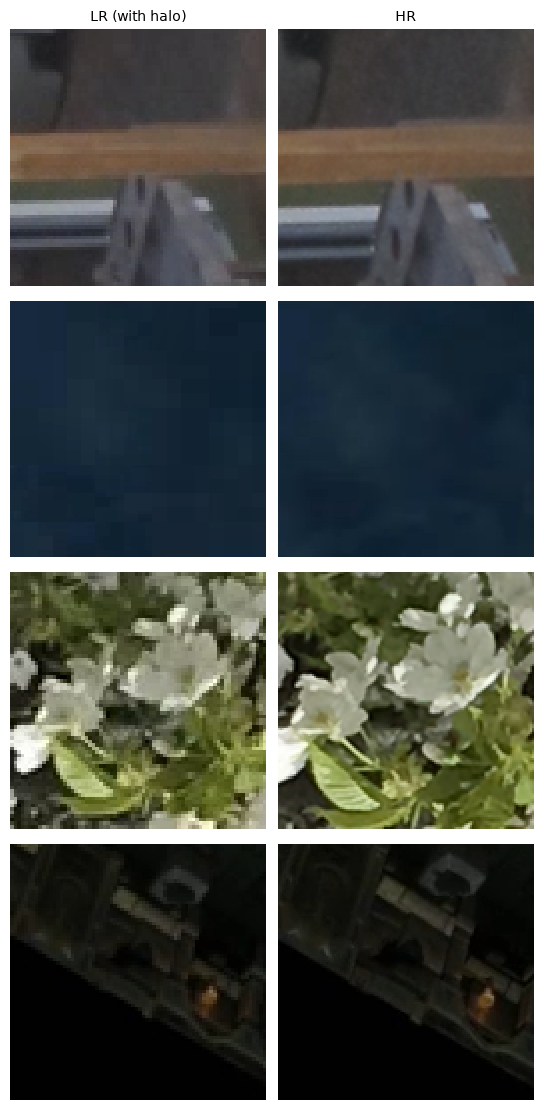

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

## 2. Model

A plain CNN shaped like ESPCN (Shi et al., 2016):

    LR picture -> conv -> ReLU -> ... -> output conv -> PixelShuffle -> HR picture

- Every convolution works at **low** resolution: 4x cheaper than upscaling first.
- The output convolution makes `3 x scale²` channels - the colours of the `scale x scale`
  HR pixels each LR pixel turns into - and `PixelShuffle` moves them into place.
- No bicubic shortcut: the network makes the **whole picture** itself.

The weights start random (`SEED` fixes them), so the untrained model puts out noise, far
below bicubic.

**Halo.** A k x k convolution sees k // 2 pixels further out, and the layers add up. The
total must fit the halo of 4 that the patches and the client's tiles have, or pixels at a
tile's edge come out wrong - so a bigger network grows wider, not deeper.

In [3]:
class PlainCNN(nn.Module):
    """LR picture in, HR picture out: convolutions at low resolution, then one PixelShuffle."""

    def __init__(self, scale, widths, kernels, tail_kernel):
        super().__init__()
        layers, channels = [], 3
        for width, kernel in zip(widths, kernels):
            layers += [nn.Conv2d(channels, width, kernel, padding=kernel // 2), nn.ReLU(inplace=True)]
            channels = width
        # the output: 3 colours for each of the scale x scale HR pixels of every LR pixel
        layers += [nn.Conv2d(channels, 3 * scale * scale, tail_kernel, padding=tail_kernel // 2),
                   nn.PixelShuffle(scale)]
        self.net = nn.Sequential(*layers)
        self.halo = sum(kernel // 2 for kernel in kernels) + tail_kernel // 2

    def forward(self, x):
        return self.net(x)


model = PlainCNN(SCALE, WIDTHS, KERNELS, TAIL_KERNEL).to(DEVICE)
assert model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
print(model)
print(f"{models.count_parameters(model):,} parameters, halo {model.halo}, "
      f"{speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

PlainCNN(
  (net): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): Conv2d(24, 32, kernel_size=(1, 1), stride=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(32, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): PixelShuffle(upscale_factor=2)
  )
)
13,404 parameters, halo 4, 13,296 multiply-adds per LR pixel


                     wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic              37.30    36.38    47.06    47.27     35.00   0.9135
untrained model       9.78     8.63    26.59    25.38      8.39   0.0885


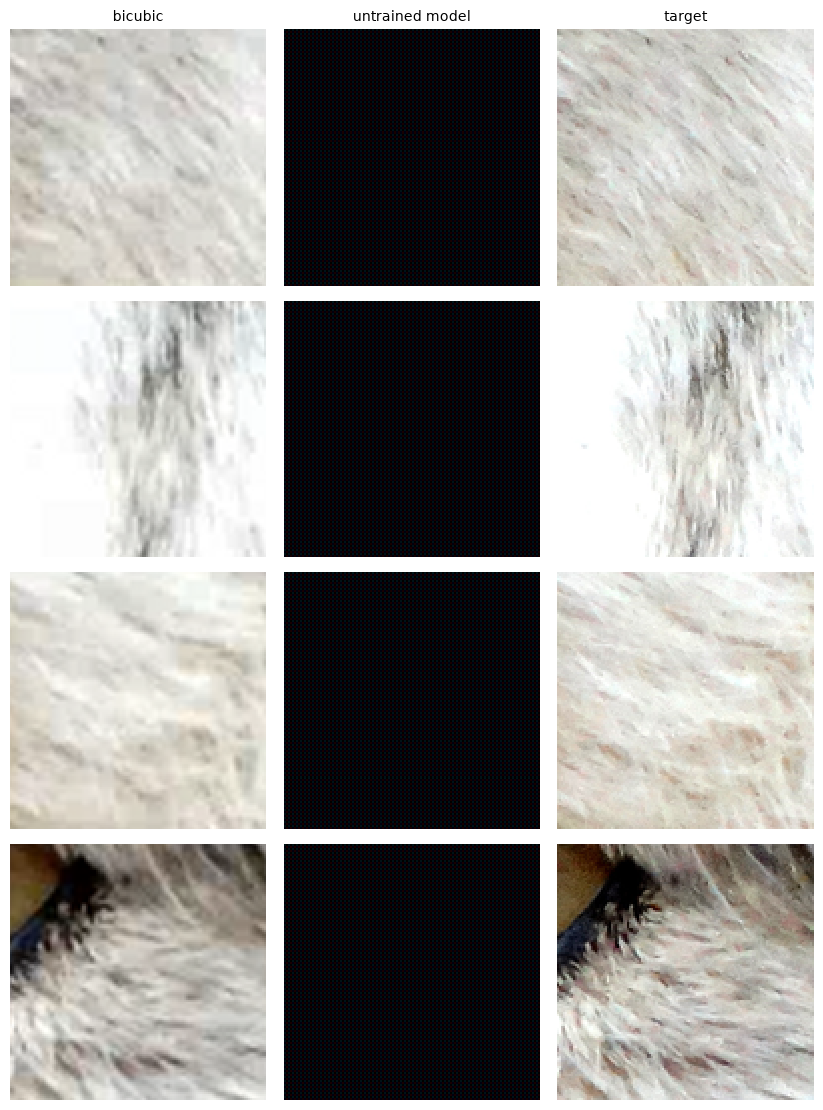

In [4]:
"""Before training: bicubic is the bar to beat, and the untrained network is random."""

bicubic = models.Resize(SCALE).to(DEVICE)
baseline = training.evaluate(bicubic, val_loader, trim)
start = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "untrained model": start})

lr, hr = next(iter(val_loader))
lr, hr = lr[:4].to(DEVICE), hr[:4].to(DEVICE)
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)),
                           "untrained model": trim(model.eval()(lr)), "target": hr})

## 3. Speed - is it fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the network's shape, not its weights, so it is checked before training:
if it is too slow, change `WIDTHS` and `KERNELS` now.

A batch of one is the honest number - frames arrive one at a time. A larger batch is
cheaper per frame, but each frame waits for the others.

In [5]:
"""One frame at a time, at the sizes a client asks for."""

model.eval()
print(f"{'output':>12}{'ms/frame':>10}   fits")
with torch.no_grad():
    for width, height in BENCH_RESOLUTIONS:
        x = torch.rand(1, 3, height, width, device=DEVICE)
        ms = speed.time_ms(lambda: model(x), seconds=1.0)
        print(f"{f'{width * SCALE}x{height * SCALE}':>12}{ms:10.1f}   {speed.frame_budget(ms)}")

      output  ms/frame   fits
     960x540       0.6   60 fps
    1280x720       1.1   60 fps
   1920x1080       2.3   60 fps
   2560x1440       4.2   60 fps


In [6]:
"""What a batch buys at 320x180 -> 640x360."""

per_frame = {}
with torch.no_grad():
    for batch in BENCH_BATCHES:
        x = torch.rand(batch, 3, BENCH_LR_SIZE[1], BENCH_LR_SIZE[0], device=DEVICE)
        per_frame[batch] = speed.time_ms(lambda: model(x), seconds=1.0) / batch

print(f"{'batch':>5}{'ms/frame':>10}{'vs batch 1':>12}")
for batch, ms in per_frame.items():
    print(f"{batch:5}{ms:10.2f}{per_frame[1] / ms:11.2f}x")

batch  ms/frame  vs batch 1
    1      0.29       1.00x
    2      0.28       1.02x
    4      0.28       1.05x
    8      0.28       1.04x
   16      0.27       1.06x


### On the target hardware

Spec sheets state compute in **TOPS** (10¹² operations per second; a multiply-add is 2).
`webexport.count_work` counts the operations and the memory traffic in the ONNX graph of
one client tile (640x360 out, plus the halo); a frame costs that times its tiles.

The runtime is a **roofline** estimate: a device needs at least *operations / peak
compute* and at least *bytes / bandwidth*, whichever is slower. This computer's GPU is
timed to see what share of its peak it reaches, and every device in `speed.HARDWARE` is
assumed to reach the same share. A browser usually reaches less, so read it as a best
case; the benchmark page, opened on the device, gives the real number.

In [7]:
"""The work in one client tile, counted in its ONNX graph, and the TOPS a stream needs."""

plan = tiles.plan_tiling((1920, 1080), scale=SCALE, halo=model.halo)
tile_shape = plan["input"][2:]   # (height, width) of one tile, halo included
# into checkpoints/, not dist/, so the benchmark page does not list it
tile_graph = webexport.export(model, "speed_check.onnx", tile_shape, halo=model.halo,
                              models_dir=training.CHECKPOINT_DIR / "speed")
work = webexport.count_work(tile_graph["path"])
ops_per_pixel = work["operations"] / work["input_pixels"]   # every convolution keeps the size
bytes_per_pixel = work["activation_bytes"] / work["input_pixels"]
print(f"one {tile_shape[1]}x{tile_shape[0]} tile: {work['operations'] / 1e9:.2f} G operations, "
      f"{work['activation_bytes'] / 1e6:.0f} MB of activations moved, {work['weight_bytes'] / 1e3:.0f} KB of weights")
for op, operations in work["by_op"].items():
    print(f"  {op:<13}{operations / 1e9:8.3f} G  ({operations / work['operations']:.1%})")
print(f"per LR pixel: {ops_per_pixel:,.0f} operations, {bytes_per_pixel:,.0f} bytes moved")


def frame_work(width, height):
    """Operations and bytes for one width x height output frame, cut into the client's tiles."""
    plan = tiles.plan_tiling((width, height), scale=SCALE, halo=model.halo)
    pixels = plan["runs"] * plan["input"][2] * plan["input"][3]   # LR pixels computed, halos included
    return {"runs": plan["runs"], "operations": pixels * ops_per_pixel,
            "bytes": pixels * bytes_per_pixel + plan["runs"] * work["weight_bytes"]}


print(f"\n{'output':>11}{'tiles':>7}{'G ops/frame':>13}{'TOPS at 30 fps':>16}{'TOPS at 60 fps':>16}")
for width, height in BENCH_RESOLUTIONS:
    frame = frame_work(width * SCALE, height * SCALE)
    print(f"{f'{width * SCALE}x{height * SCALE}':>11}{frame['runs']:>7}{frame['operations'] / 1e9:>13.1f}"
          f"{frame['operations'] * 30 / 1e12:>16.3f}{frame['operations'] * 60 / 1e12:>16.3f}")

one 328x188 tile: 1.65 G operations, 104 MB of activations moved, 54 KB of weights
  Conv            1.646 G  (99.6%)
  Relu            0.006 G  (0.4%)
  DepthToSpace    0.000 G  (0.0%)
per LR pixel: 26,796 operations, 1,692 bytes moved

     output  tiles  G ops/frame  TOPS at 30 fps  TOPS at 60 fps
    960x540      2          3.7           0.111           0.222
   1280x720      4          6.6           0.198           0.397
  1920x1080      9         14.9           0.446           0.892
  2560x1440     16         26.4           0.793           1.586


In [8]:
"""Simulated runtime per frame on the target hardware (float32)."""

# Calibrate: the share of its peak this GPU reaches, on one whole 1080p frame (no tiles)
if DEVICE.type == "cuda":
    x = torch.rand(1, 3, 540, 960, device=DEVICE)
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model.eval()(x), seconds=1.0)
    whole_frame = {"operations": 960 * 540 * ops_per_pixel,
                   "bytes": 960 * 540 * bytes_per_pixel + work["weight_bytes"]}
    best_ms, _ = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / measured_ms
    print(f"{speed.THIS_GPU}: measured {measured_ms:.2f} ms per 1080p frame, the roofline says at least "
          f"{best_ms:.2f} ms, so it reaches {efficiency:.0%} of its peak "
          f"({whole_frame['operations'] / (measured_ms / 1000) / 1e12:.1f} TOPS)")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")
cpu_ms = webexport.time_graph(tile_graph["path"], tile_shape)
print(f"this CPU (onnxruntime): {cpu_ms:.1f} ms per tile, {work['operations'] / (cpu_ms / 1000) / 1e12:.3f} TOPS")

resolutions = [(width * SCALE, height * SCALE) for width, height in BENCH_RESOLUTIONS]
print(f"\nestimated ms per frame at {efficiency:.0%} of the peak (c = compute-bound, m = memory-bound)")
print(f"{'':<36}" + "".join(f"{f'{width}x{height}':>14}" for width, height in resolutions) + "   1080p")
for name, (tflops, gbps) in speed.HARDWARE.items():
    row = f"{name:<36}"
    for width, height in resolutions:
        best_ms, limit = speed.roofline_ms(frame_work(width, height), tflops, gbps)
        row += f"{best_ms / efficiency:>10.1f} ({limit[0]})"
    full_hd_ms = speed.roofline_ms(frame_work(1920, 1080), tflops, gbps)[0] / efficiency
    print(f"{row}   {speed.frame_budget(full_hd_ms)}")

NVIDIA RTX 3090: measured 2.33 ms per 1080p frame, the roofline says at least 0.94 ms, so it reaches 40% of its peak (6.0 TOPS)
this CPU (onnxruntime): 4.1 ms per tile, 0.406 TOPS

estimated ms per frame at 40% of the peak (c = compute-bound, m = memory-bound)
                                           960x540      1280x720     1920x1080     2560x1440   1080p
Intel UHD 620 (laptop iGPU)               21.8 (c)      39.0 (c)      87.9 (c)     156.2 (c)   under 30 fps
Intel Iris Xe, 96 EU (laptop iGPU)         8.5 (m)      15.2 (m)      34.3 (m)      60.9 (m)   under 30 fps
Apple M1, 8-core GPU                       8.5 (m)      15.2 (m)      34.3 (m)      60.9 (m)   under 30 fps
NVIDIA GTX 1650                            4.5 (m)       8.1 (m)      18.2 (m)      32.4 (m)   30 fps
NVIDIA RTX 3060                            1.6 (m)       2.9 (m)       6.5 (m)      11.5 (m)   60 fps
NVIDIA RTX 3090                            0.6 (m)       1.1 (m)       2.5 (m)       4.4 (m)   60 fps


## 4. Train

The loss is `metrics.ssim_l1_loss`: 0.84 x (1 - SSIM on luma) + 0.16 x L1 on RGB. L1
alone compares pixel by pixel, and a blurred edge is its safest bet; SSIM compares edges
and contrast in 11x11 windows, so it pays for keeping structure. After every epoch the
validation split is scored, and the epoch with the best luma SSIM (`ssim-y`) is kept.
Against plain L1 it gains SSIM for a little luma PSNR and some chroma (`summary.md`).

The network starts from noise, so the first epochs climb from far below bicubic. Training
runs until the score stops improving, halving the learning rate at every plateau
(`training.train`); `MAX_EPOCHS` is only a safety limit.

Training until the model stops improving, at most 500 epochs. Untrained model: val_psnr_rgb: 8.3889.
Learning rate 1.0e-03, halved after 6 epochs without improvement; training stops when 1.0e-05 does not help either.
Epoch 1/500
347/347 [==============================] - 4s 10ms/step - loss: 0.0619 - val_wpsnr: 32.3086 - val_psnr_y: 31.5817 - val_psnr_u: 38.0720 - val_psnr_v: 39.6255 - val_psnr_rgb: 30.0709 - val_ssim_y: 0.8374 - learning_rate: 1.0e-03
Epoch 1: val_psnr_rgb improved from 8.3889 to 30.0709
Epoch 2/500
347/347 [==============================] - 3s 10ms/step - loss: 0.0323 - val_wpsnr: 34.1060 - val_psnr_y: 33.6465 - val_psnr_u: 38.8109 - val_psnr_v: 39.2191 - val_psnr_rgb: 31.2411 - val_ssim_y: 0.8848 - learning_rate: 1.0e-03
Epoch 2: val_psnr_rgb improved from 30.0709 to 31.2411
Epoch 3/500
347/347 [==============================] - 3s 10ms/step - loss: 0.0282 - val_wpsnr: 34.0241 - val_psnr_y: 33.3311 - val_psnr_u: 38.8729 - val_psnr_v: 39.8439 - val_psnr_rgb: 31.9394 

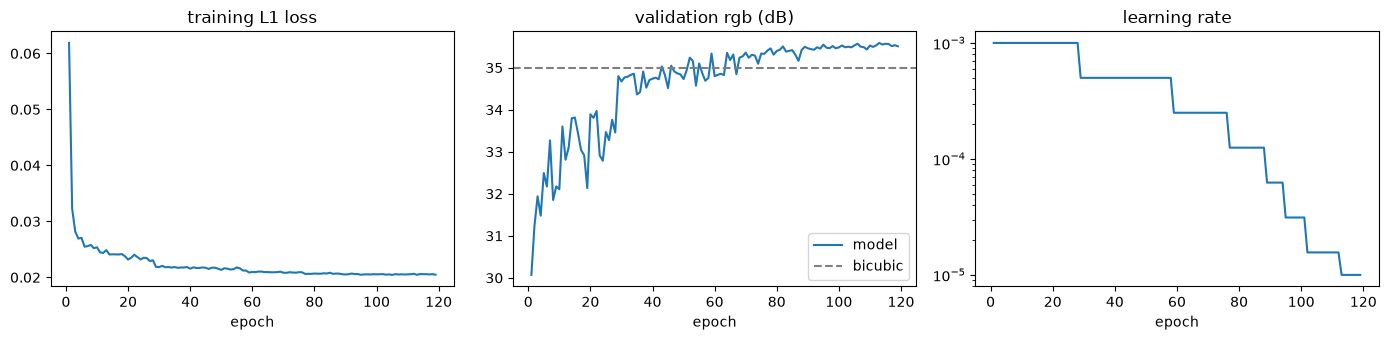

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             37.30    36.38    47.06    47.27     35.00   0.9135   +0.00 dB rgb vs bicubic
model               38.01    37.13    45.73    45.85     35.59   0.9215   +0.59 dB rgb vs bicubic


In [9]:
history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS,
                               learning_rate=LEARNING_RATE, loss_fn=metrics.ssim_l1_loss, select="ssim")
training.plot_history(history, baseline, key="ssim", loss_name="SSIM-Y + L1 loss")

final = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "model": final},
                    extra=lambda name, s: f"   {s['ssim'] - baseline['ssim']:+.4f} ssim-y vs bicubic")

### What it looks like

Check text lines and window edges - that is what a desktop stream is made of.

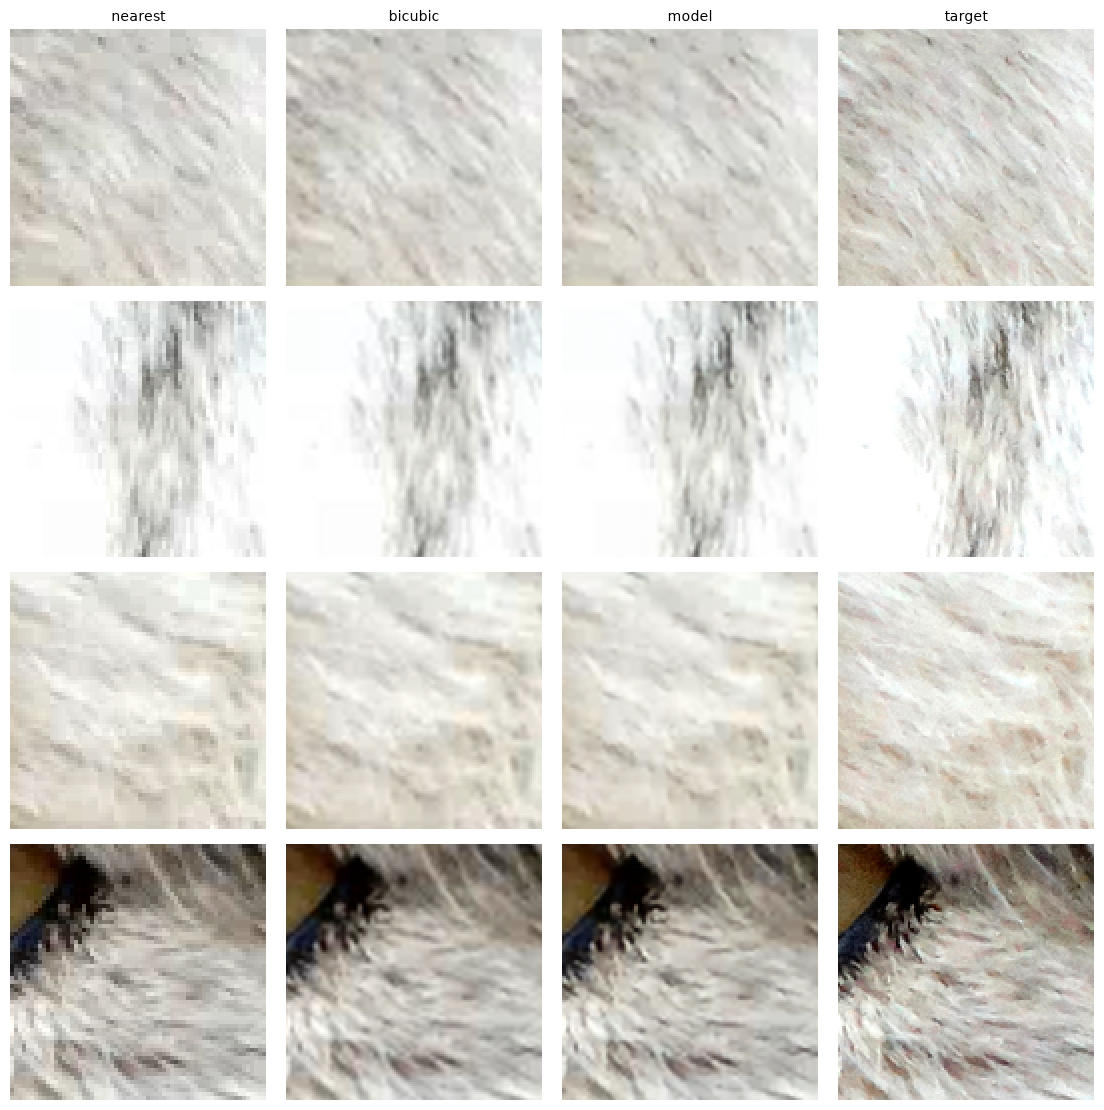

In [10]:
lr, hr = next(iter(val_loader))
lr, hr = lr[:4].to(DEVICE), hr[:4].to(DEVICE)
with torch.no_grad():
    training.show_patches({
        "nearest": trim(F.interpolate(lr, scale_factor=SCALE, mode="nearest")),
        "bicubic": trim(models.bicubic(lr, SCALE)),
        "model": trim(model.eval()(lr)),
        "target": hr,
    })

## 5. Save and reload

The checkpoint holds the weights *and* everything needed to rebuild the model. We load
it into a fresh model and check it computes the same thing.

In [11]:
training.save_checkpoint(CHECKPOINT, model, architecture="PlainCNN", scale=SCALE,
                         widths=list(WIDTHS), kernels=list(KERNELS), tail_kernel=TAIL_KERNEL,
                         halo=model.halo, loss="ssim_l1_loss", select="ssim", epochs=len(history),
                         best_epoch=best["epoch"], val=final, val_bicubic=baseline,
                         degradation=manifest["degradation"])

checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = PlainCNN(checkpoint["scale"], tuple(checkpoint["widths"]), tuple(checkpoint["kernels"]),
                  checkpoint["tail_kernel"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(model, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_nn.pt (59 KB)
reloaded model is identical


### A whole frame

The model is fully convolutional, so it runs on a picture of any size, not only patches.

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             25.82    25.09    29.55    29.01     23.92   0.9437
model               26.21    25.66    28.79    28.20     24.05   0.9524


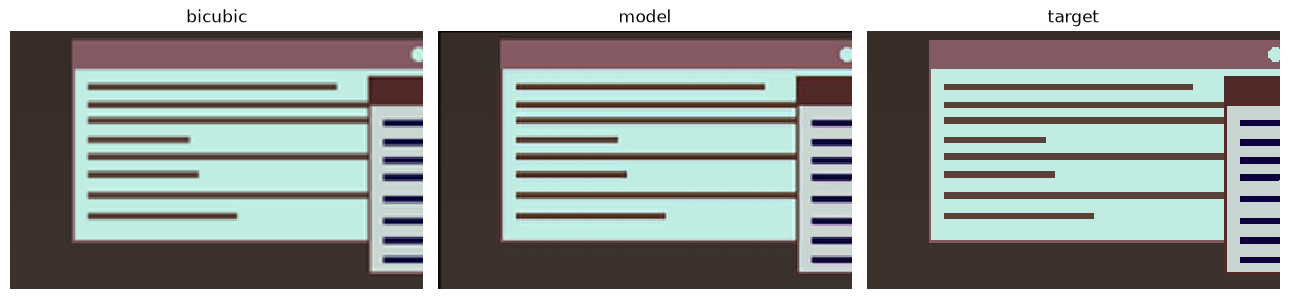

In [12]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC)

with torch.no_grad():
    upscaled = loaded.eval()(training.to_tensor(small))
target = training.to_tensor(truth)
metrics.print_table({"bicubic": metrics.report(models.bicubic(training.to_tensor(small), SCALE), target),
                     "model": metrics.report(upscaled, target)})
Image.fromarray(training.to_image(upscaled)).save(training.SAMPLE_DIR / "upscaled_nn.png")

box = (slice(0, 200), slice(0, 320))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
panels = {"bicubic": np.asarray(small.resize(truth.size, Image.BICUBIC)),
          "model": training.to_image(upscaled), "target": np.asarray(truth)}
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(image[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

The graph is only `Conv`, `Relu` and `DepthToSpace` (ONNX's `PixelShuffle`), all in the
browser's fast operator set, so the summary line below should flag nothing.

In [13]:
size = webexport.TILE_STEP + 2 * checkpoint["halo"]
info = webexport.export(loaded, f"upscale_nn_tile{webexport.TILE_STEP}.onnx", size,
                        label=f"nn - plain CNN {'-'.join(map(str, WIDTHS))}", halo=checkpoint["halo"])
webexport.check_graph(info["path"], loaded, np.random.rand(1, 3, size, size).astype(np.float32))
ms = webexport.time_graph(info["path"], size)
webexport.annotate(info, cpu_ms=round(ms, 2))
print(webexport.summary_line(info, ms))
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_nn_tile128.onnx                                54.2 KB    1.16 ms   Convx5, DepthToSpacex1, Relux4
compare in a browser: uv run src/upscale/benchmark/main.py
